# Knekke cæsar-chiffer med et transformer-nettverk
*(og hvorfor man ikke bør)*

Alfabetet er a–z, æ, ø, å og mellomrom (30 tegn). Hvert tegn i teksten er flyttet *k* plasser fram i alfabetet. Oppgaven er å finne *k* uten å kjenne den, og skrive ut klarteksten.

**Planen.** Vi løser det på den dummeste måten vi kommer på: et nettverk får se de kodede tegnene og skal svare med en av 30 forskyvninger. Ingen telling av bokstaver, ingen frekvenstabell og ingenting om cæsar-chiffer er bygget inn. Alt må læres av eksempler vi lager selv. Så tar vi bort ting trinn for trinn, til det ikke lenger er maskinlæring, og helt til slutt viser vi hvor lite som egentlig skulle til.

| | |
|---|---|
| 1 | Alfabetet og chifferet |
| 2 | Syntetiske treningsdata |
| 3 | Modellen |
| 4 | Trening |
| 5 | Knekke tekster |
| 6 | Hvor godt virker det? |
| 7 | Går det an å være dummere? |
| 8 | Den enkle måten |
| 9 | Hva lærte vi? |
| 10 | Prøv selv |

*Kjøres fra mappen med `crack_caesar.py`. Trenger `torch`, `numpy` og `matplotlib`. Trener på GPU (cuda) hvis det finnes en, ellers på CPU, som tar rundt et halvt minutt til treningen i seksjon 4. Hele notebooken tar noen minutter.*

In [1]:
import contextlib
import inspect
import io
import re
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch
from IPython.display import Code, Image, display

sys.path.insert(0, str(Path.cwd()))
import crack_caesar as cc    # data, modell, trening, knekking
import not_that_difficult as nd   # den enkle måten, vi kommer tilbake til den til slutt
import plot_caesar as pc     # figurene
import trappen as tp         # enklere modeller å sammenligne med

PLOTS = Path("plots")
PLOTS.mkdir(exist_ok=True)
theme = pc.THEMES["light"]
pc.apply_theme(theme)


def figur(lag_figur, filnavn, *args, width=950):
    # tegner figuren (og lagrer den i plots/), og viser den her
    with contextlib.redirect_stdout(io.StringIO()):   # plot_caesar skriver ut filnavnet, det trenger vi ikke her
        resultat = lag_figur(theme, PLOTS, *args)
    display(Image(filename=PLOTS / filnavn, width=width))
    return resultat

## 1. Alfabetet og chifferet

Alfabetet, rekkefølgen og hyppigheten til hvert tegn leses fra `vanligst.csv`. Mellomrom er en vanlig linje der, og blir forskjøvet som alle andre tegn. Det betyr at i en kodet tekst er det vanligste tegnet gjerne mellomrommets nye bokstav.

In [2]:
print(f"Alfabet ({cc.N} tegn): {cc.ABC!r}")
print(f"Mellomrom er {cc.SPACE_P:.1%} av alle tegn i vanligst.csv\n")
print("De åtte vanligste tegnene:")
for i in np.argsort(-cc.SYMBOL_P)[:8]:
    print(f"  {pc.sym(cc.ABC[i])}  {cc.SYMBOL_P[i]:6.1%}")

klar = "hei på deg"
kodet = cc.shift_text(klar, 7)
print(f"\n{klar!r}  --(+7)-->  {kodet!r}  --(-7)-->  {cc.shift_text(kodet, -7)!r}")

Alfabet (30 tegn): 'abcdefghijklmnopqrstuvwxyzæøå '
Mellomrom er 18.6% av alle tegn i vanligst.csv

De åtte vanligste tegnene:
  ␣   18.6%
  e   12.5%
  r    7.0%
  t    6.4%
  n    6.4%
  s    5.2%
  i    5.0%
  a    4.9%

'hei på deg'  --(+7)-->  'olpgwfgkln'  --(-7)-->  'hei på deg'


Samme 100 tegn før og etter koding. Formen på fordelingen er den samme, den er bare skjøvet 7 plasser, og alfabetet går i ring. Det er hele signalet som finnes i en kodet tekst. Husk det, for nettverket får ikke vite om det.

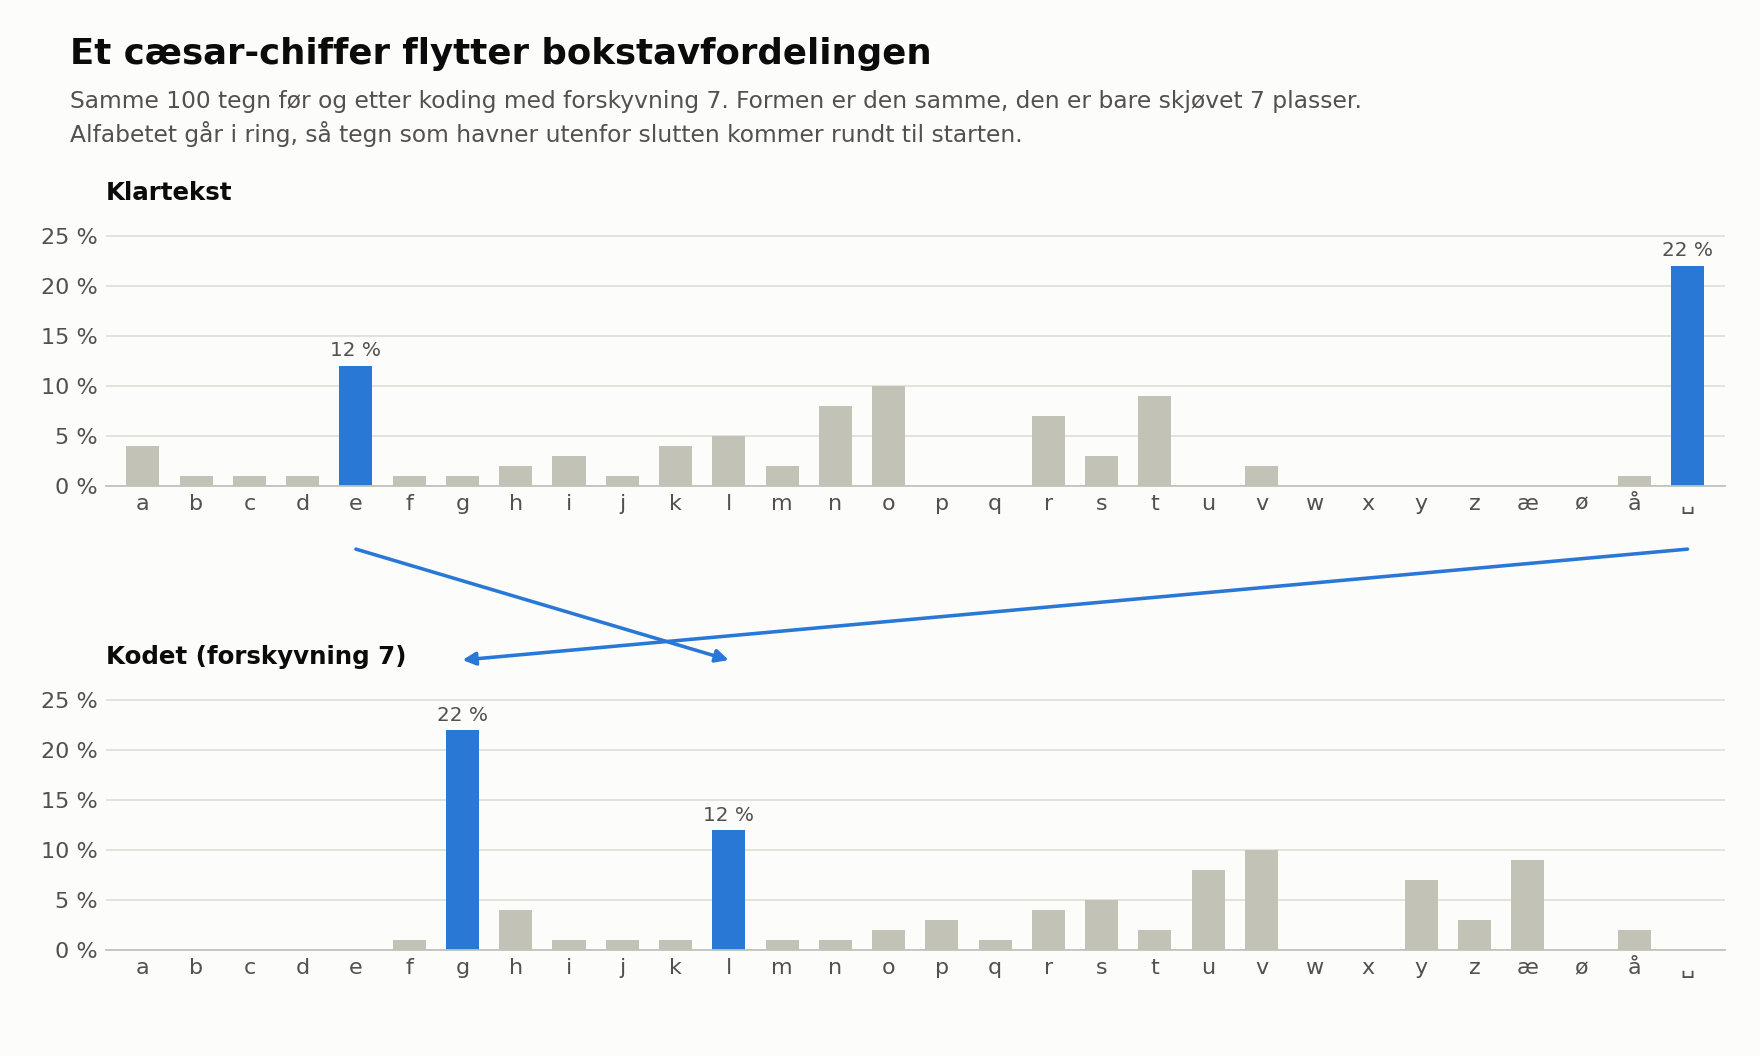

In [3]:
figur(pc.fig_shift, "1_kryptert_tekst.png")

## 2. Syntetiske treningsdata

Et nettverk trenger mange kodede tekster med kjent fasit, og dem lager vi selv. Bokstavene trekkes etter `vanligst.csv`, og mellomrommene legges inn så teksten består av ord. Ordlengden er 1 + Poisson(λ), og λ er regnet ut slik at mellomrommets andel blir den samme som i CSV-en. Hver tekst får sin egen λ, litt over eller under snittet, så nettverket ikke lærer ett bestemt mellomromsforhold.

Frekvensene i CSV-en brukes bare her, til å lage data. Selve nettverket ser dem aldri.

In [4]:
Code(inspect.getsource(cc.make_plain), language="python")

def make_plain(rng, batch, length, letter_p=LETTER_P, lam_spread=1.5):
    """Syntetiske norske tekster som tegn-indekser 0..N-1, form (batch, length).

    Bokstavene trekkes etter vanligst.csv (letter_p er fordelingen blant bokstavene alene).
    Mellomrommene legges inn så teksten består av ord: ordlengden er 1 + Poisson(lam), og lam
    er satt så mellomrommets andel blir den samme som i CSV-en. Hver tekst får sin egen lam, litt
    over eller under snittet (± lam_spread), så modellen ikke lærer ett bestemt mellomromsforhold
    og tåler tekster som ligner litt mindre på CSV-en.
    """
    lo, hi = max(WORD_LAM - lam_spread, 0.0), WORD_LAM + lam_spread
    lam = rng.uniform(lo, hi, size=(batch, 1))
    max_words = length // 2 + 2  # ord på 1 tegn + mellomrom er korteste mulige
    word_len = 1 + rng.poisson(lam, size=(batch, max_words))
    space_pos = np.cumsum(word_len + 1, axis=1) - 1  # plassen til mellomrommet etter hvert ord
    text = LETTERS[rng.choice(len(LETTERS), size=(batch, length), p=letter_p)]
    rows, cols = np.nonzero(space_pos < length)
    text[rows, space_pos[rows, cols]] = SPACE
    return text

In [5]:
rng = np.random.default_rng(1)
print("Tre eksempler på syntetisk tekst:\n")
for rad in cc.make_plain(rng, 3, 100, cc.LETTER_P):
    print("  " + "".join(cc.ABC[i] for i in rad))

tekster = cc.make_plain(rng, 20000, 100, cc.LETTER_P)
print(f"\nMellomrom i genererte tekster: {np.mean(tekster == cc.SPACE):.1%}   (vanligst.csv: {cc.SPACE_P:.1%})")

Tre eksempler på syntetisk tekst:

  aatggs r giebt lpt rrce ressghd dmnnb ren ety teouase osikub yte ettaag sitgh vslewi krr vobsysal tl
  cuv asrya fdrha snep ooa rrrt tja fadmef ttirte oee akaee elphu garegnå lopen odeæss vironpg iea eve
  gøm rde thll sae nli kånnå åvogohsel kn fvoim ssf om e r r vel eeåt bnee nkbi ggne rflniedn atvm rml

Mellomrom i genererte tekster: 18.7%   (vanligst.csv: 18.6%)


## 3. Modellen

Tekst inn, en av 30 forskyvninger ut, og ingenting imellom annet enn en liten transformer: tegnene gjøres om til vektorer, to lag med oppmerksomhet blander dem, og snittet over teksten går inn i et lag som gir 30 poengsummer. Den høyeste er gjettet.

In [6]:
Code(inspect.getsource(cc.Cracker), language="python")

class Cracker(nn.Module):
    """En liten transformer som leser den kodede teksten og svarer med en av N forskyvninger.

    Tegnene gjøres om til vektorer, noen lag med oppmerksomhet blander dem, snittet over hele
    teksten går inn i et lag som gir en poengsum per forskyvning. Det er hele modellen, og
    ingenting i den vet noe om cæsar-chiffer. Eneste forhåndskunnskap er at vi ikke har gitt
    den posisjonskoding: rekkefølgen på tegnene sier ingenting om forskyvningen.
    """

    def __init__(self, d=64, heads=4, layers=2):
        super().__init__()
        self.embed = nn.Embedding(N, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, N)

    def forward(self, ids):  # ids: (batch, length) tegn-indekser -> (batch, N) poengsum per forskyvning
        return self.head(self.encoder(self.embed(ids)).mean(dim=1))

In [7]:
modell = cc.Cracker()
print(f"{sum(p.numel() for p in modell.parameters()):,} parametre".replace(",", " "))

103 838 parametre


**Hva nettverket ikke vet:**
- at tegn kan telles, eller at det er fordelingen av tegn som avslører forskyvningen
- at norsk har en bestemt bokstavfordeling (den får aldri se `vanligst.csv`)
- at en forskyvning er en rotasjon av alfabetet. For nettverket er «forskyvning 5» og «forskyvning 6» like ulike som «5» og «20». Det er 30 helt separate klasser.

Den eneste hjelpen vi har gitt er å droppe posisjonskoding, siden rekkefølgen på tegnene ikke sier noe om forskyvningen.

## 4. Trening

Dataene lages fortløpende, så en «epoke» er bare 40 nye batcher à 256 tekster, og vi kjører fem av dem. Lengden varierer mellom 50 og 150 tegn. Treningen bruker GPU-en hvis det finnes en.

In [8]:
modell, historikk = cc.train()

Eksempel på syntetisk tekst (klartekst, og kodet med forskyvning 7):
  u eermlerd skt segil se tcafiybrle iefj kvabaoe sgerl drtt eek oerk ks ri euenn lsmvr vseeneier emis
  øgllytslykgzrægzlnpsgzlgæjhmpbiyslgplmqgråhihvlgznlysgkyæægllrgvlyrgrzgypgløluugsztåygåzllulplygltpz

  lrn jåj se oeaå eteerrterl rsgeåt sd regn rnen dei ueeiuik æi orie kåt eprbi noe åaihi kt keso eet s
  syugqfqgzlgvlhfglællyyælysgyznlfægzkgylnugyulugklpgøllpøprgdpgvyplgrfæglwyipguvlgfhpopgrægrlzvgllægz

  te e aner nf ast lsao gta goe ole tnrk srea it mirrpsnm tisld fmt l runt rrneif ot kni naha nde sis 
  ælglghulygumghzægszhvgnæhgnvlgvslgæuyrgzylhgpægtpyywzutgæpzskgmtægsgyøuægyyulpmgvægrupguhohguklgzpzg

Trener på cuda (NVIDIA GeForce RTX 3060 Ti)
Nettverket har 103 838 parametre
epoke 1/5  tap 0.022  treffsikkerhet på 100 tegn 99.1%
epoke 2/5  tap 0.004  treffsikkerhet på 100 tegn 100.0%
epoke 3/5  tap 0.001  treffsikkerhet på 100 tegn 100.0%
epoke 4/5  tap 0.000  treffsikkerhet på 100 tegn 100.0%
epoke 5/5 

Nettverket lærer overraskende fort. Det starter på tilfeldig gjetting og er over 95 % etter et par tusen tekster, uten at noen har fortalt det hva et cæsar-chiffer er. Resten av treningen er pussing.

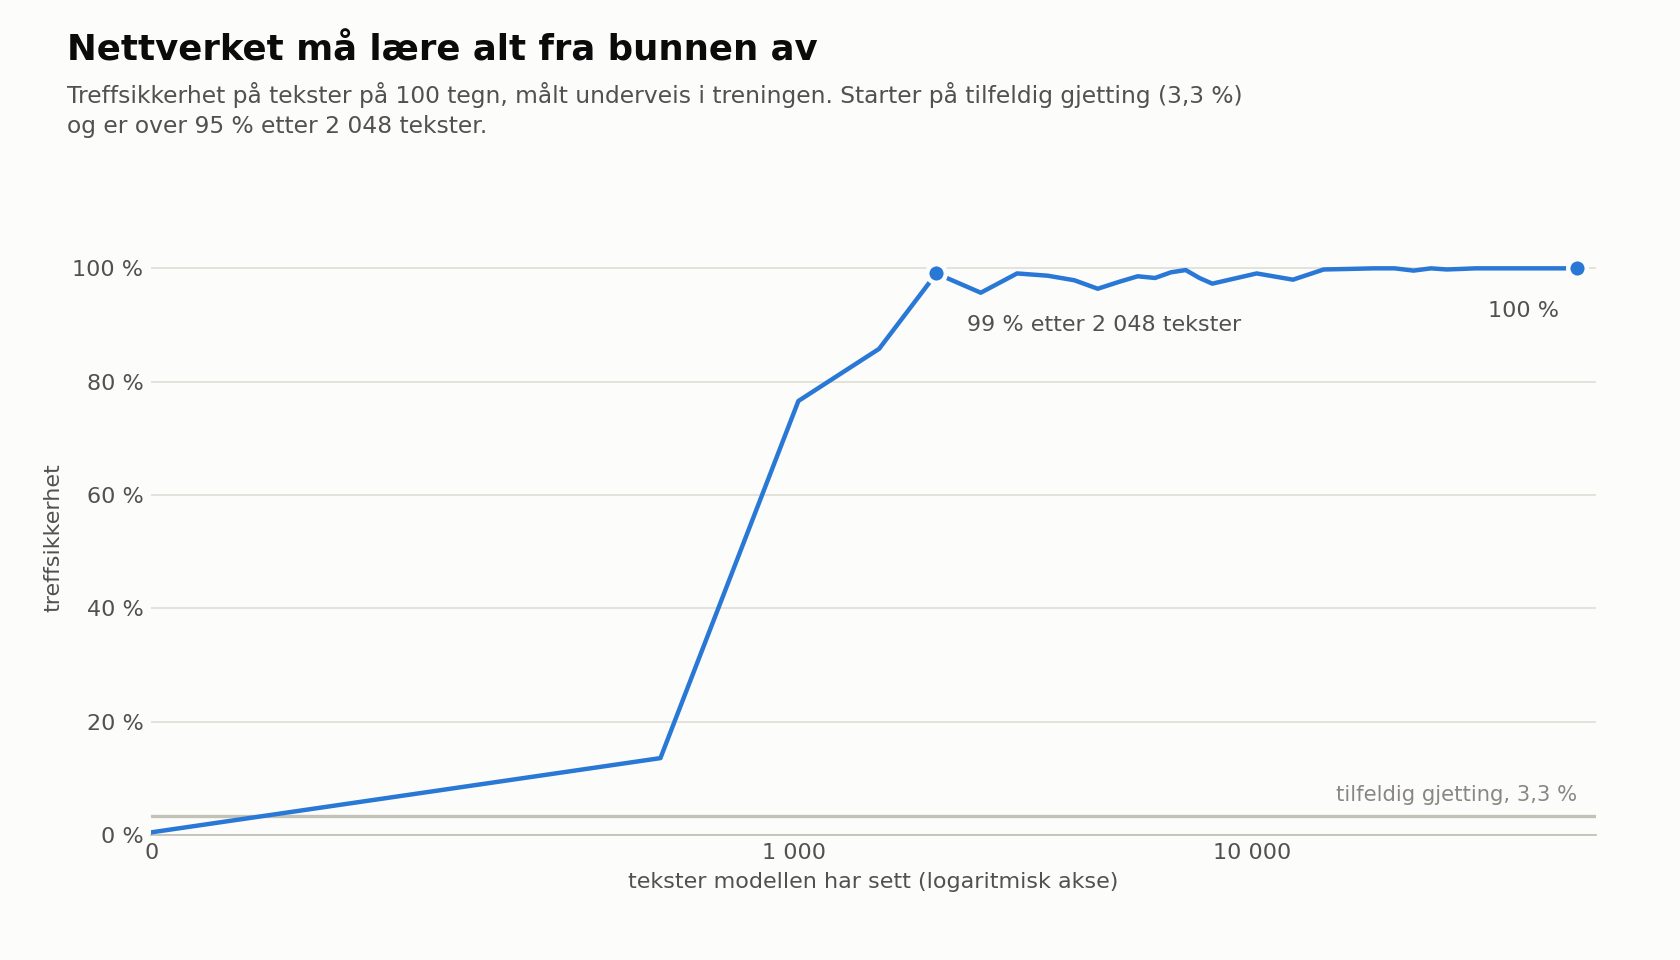

In [9]:
figur(pc.fig_training, "2_treningskurve.png", {"Transformer": historikk})

## 5. Knekke tekster

Fire filer: `s13.txt` er norsk, kodet med 13 (47 tegn). `s7.txt` er **engelsk**, kodet med 7. `i3.txt` er norsk med tegnsetting og en apostrof. `i4.txt` er bare 26 tegn.

In [10]:
for fil in ["s13.txt", "s7.txt", "i3.txt", "i4.txt"]:
    cc.crack_file(modell, fil)
    print()

s13.txt: forskyvning 13 (sikkerhet 99%), klartekst:
årsaken er i min vilje - jeg ønsker å ikke komme


s7.txt: forskyvning 7 (sikkerhet 100%), klartekst:
experience is the teacher of all things
no one is so brave that he is not disturbed by something unexpected
i had rather be first in a village than second at rome
men freely believe that which they desire
i came i saw i conquered

i3.txt: forskyvning 17 (sikkerhet 100%), klartekst:
det turde bli’ værst for ham. tar de livsløgnen fra et gennemsnitsmenneske, så tar de lykken fra ham med det samme

i4.txt: forskyvning 17 (sikkerhet 100%), klartekst:
westminister dwarf pincher



Alle fire er riktige, også den engelske. `s13.txt` er likevel et grensetilfelle: i en tidligere kjøring med lavere læringsrate (0,001, ikke vist her) tok nettverket feil på den, og sa seg 73 % sikker på det.

## 6. Hvor godt virker det?

Treningen skrev ut en tabell over syntetiske tekster. Her er den samme testen på **ekte** norsk tekst fra oppgave-PDF-en (som ikke er brukt i treningen). Vi kutter den i vinduer, koder hvert vindu med alle 30 forskyvninger, og teller hvor ofte nettverket finner riktig.

In [11]:
pdf = Path("hjemmeoppgave-kryptering-med-c-sars-kode.pdf")
ekte = {}
try:
    rå = subprocess.run(["pdftotext", str(pdf), "-"], capture_output=True, text=True, check=True).stdout.lower()
except (OSError, subprocess.CalledProcessError):
    rå = None
    print("Hopper over: trenger pdftotext og PDF-en i mappen.")

if rå:
    tekst = re.sub(r"[^a-zæøå]+", " ", rå).strip()       # alt som ikke er bokstav blir ett mellomrom
    idx = np.array([cc.ABC.index(c) for c in tekst])
    print(f"{len(tekst)} tegn ekte norsk tekst, {np.mean(idx == cc.SPACE):.1%} mellomrom\n")
    print(f"{'vindu':>6} {'tester':>7} {'nettverk':>9}")
    for L in (30, 50, 100):
        vinduer = [idx[i:i + L] for i in range(0, len(idx) - L + 1, L)]
        X = torch.from_numpy(np.array([(v + s) % cc.N for v in vinduer for s in range(cc.N)]))
        y = torch.tensor([s for _ in vinduer for s in range(cc.N)])
        ekte[L] = (X, y)
        print(f"{L:>6} {len(X):>7} {cc.accuracy(modell, X, y):>9.1%}")

3403 tegn ekte norsk tekst, 16.4% mellomrom

 vindu  tester  nettverk
    30    3390     90.4%
    50    2040     92.4%
   100    1020     91.7%


Tre ting å legge merke til:
1. **Lengde.** Fra 100 tegn og oppover er den nesten perfekt på syntetisk tekst. Under 30 tegn faller det raskt: på 10 tegn er det omtrent to av tre.
2. **Ekte tekst er vanskeligere.** Nettverket har bare sett tekst som følger CSV-en pent. Ekte tekst gjør det ikke helt, og treffsikkerheten blir lavere.
3. **Skjørt.** Små endringer i treningen, som læringsraten, kan snu et grensetilfelle som `s13.txt`. Statistikken har ingen slike knapper.

Før vi kommer til det vi lovet: hvor dumt kan det bli før det slutter å virke?

## 7. Går det an å være dummere?

Transformeren er overkill, og vi kan teste hvor mye. Vi tar bort ting trinn for trinn og trener hver modell på nøyaktig samme måte: tekster på 100 tegn, 200 steg, samme data.

| Trinn | Modell |
|---|---|
| 1 | **Transformeren** fra før |
| 2 | **MLP** som leser alle 100 plasser som én lang vektor, med egne vekter for hver plass og hvert tegn |
| 3 | **Ett lineært lag** på den samme vektoren, ingen skjult del |
| 4 | **Ett lineært lag på tegnandelene**: først teller vi hvor stor andel hvert tegn utgjør, så ett lag på 30 × 30 vekter |

Trinn 2 og 3 får ikke engang lov til å telle, og de må lære at et tegn på plass 5 betyr det samme som på plass 77.

In [12]:
Code("\n\n".join(inspect.getsource(k) for k in (tp.FlatMLP, tp.FlatLinear, tp.ShareLinear)), language="python")

class FlatMLP(nn.Module):
    """Alle plassene i teksten som én lang vektor, en egen vekt for hver plass og hvert tegn."""

    def __init__(self, length, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(length * N, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, N))

    def forward(self, ids):  # (batch, length) -> (batch, N)
        return self.net(F.one_hot(ids, N).float().flatten(1))


class FlatLinear(nn.Module):
    """Det samme, men uten skjult del."""

    def __init__(self, length):
        super().__init__()
        self.net = nn.Linear(length * N, N)

    def forward(self, ids):
        return self.net(F.one_hot(ids, N).float().flatten(1))


class ShareLinear(nn.Module):
    """Tegnandelene (hvor stor del av teksten hvert tegn er) og ett lineært lag på N x N vekter."""

    def __init__(self, length=None):
        super().__init__()
        self.net = nn.Linear(N, N)

    def forward(self, ids):
        return self.net(F.one_hot(ids, N).float().mean(dim=1))

In [13]:
resultat = tp.ladder(real=ekte.get(100))   # tre treninger per trinn, 200 steg, tekster på 100 tegn


def til_95(historikk):
    return next((h["texts"] for h in historikk if h["acc"] >= 0.95), None)


print(f"{'':<27} {'parametre':>10} {'tid':>6} {'95 % etter':>11} {'syntetisk':>10} {'ekte tekst':>11}")
for i, (navn, r) in enumerate(resultat.items(), 1):
    ekte_tall = f"{r['real']:.1%}" if r["real"] is not None else "-"
    print(f"{i}  {navn:<24} {r['params']:>10,} {r['seconds']:>5.1f}s {til_95(r['history']):>6,} tekster {r['synthetic']:>9.1%} {ekte_tall:>11}".replace(",", " "))
print("\n(gjennomsnitt av 3 treninger, 200 steg på tekster på 100 tegn, ekte tekst = vinduene fra seksjon 6)")

                             parametre    tid  95 % etter  syntetisk  ekte tekst
1  Transformer                 103 838   3.5s  2 048 tekster    100.0%       91.4%
2  MLP på alle plasser         841 758   0.6s  2 048 tekster    100.0%       91.2%
3  Ett lag på alle plasser      90 030   0.5s  1 024 tekster    100.0%       91.9%
4  Ett lag på tegnandeler          930   0.5s 12 288 tekster    100.0%       91.7%

(gjennomsnitt av 3 treninger, 200 steg på tekster på 100 tegn, ekte tekst = vinduene fra seksjon 6)


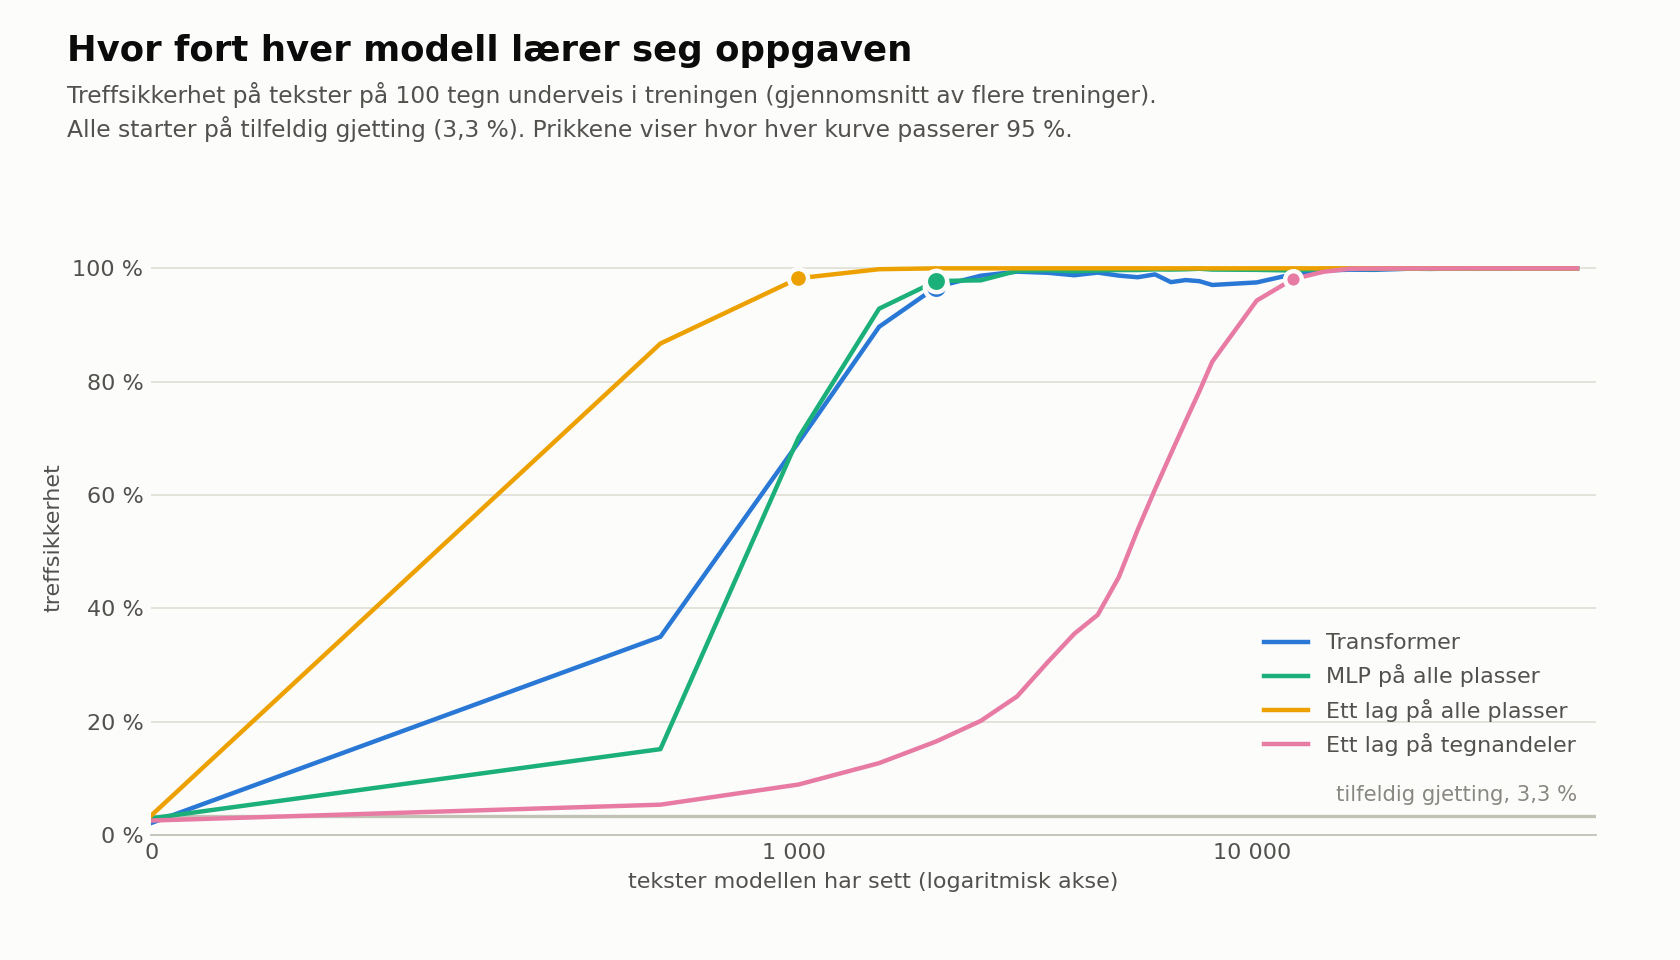

In [14]:
kurver = {navn: r["history"] for navn, r in resultat.items()}
figur(pc.fig_training, "3_treningskurver_trappen.png", kurver, "3_treningskurver_trappen")

Alle fire trinn ender på det samme, også det nederste som bare har knapt tusen vekter. Signalet er så sterkt at hvordan modellen er bygget nesten ikke spiller noen rolle. Trinn 2 har åtte ganger så mange parametre som transformeren og trener likevel fortere. Det er ikke like fort for alle å komme dit: det minste trinnet trenger mange flere tekster før det passerer 95 % (se kurvene), selv om det kommer like høyt til slutt. Siden alle fire lander på nesten samme tall på ekte tekst, tyder det på at det som begrenser dem ikke er modellen, men at alle har lært av syntetiske tekster.

Trinn 4 er verdt å stoppe ved: «tell hvor stor andel hvert tegn er, og gi hver forskyvning en vektet sum» er ikke lenger noen nettverksarkitektur. Det er i praksis en klassisk statistisk modell (logistisk regresjon), bare tegnet som et nettverk.

## 8. Den enkle måten

Bunnen av trappen er allerede statistikk, så her er den uten forkledning. `not_that_difficult.py` leser den samme CSV-en. For hver av de 30 forskyvningene angrer den forskyvningen, teller bokstavene og måler hvor langt fordelingen er fra den norske (chi-kvadrat). Forskyvningen som kommer nærmest, vinner. Ingen treningsdata, ingen trening, ingen parametre.

In [15]:
Code(filename="not_that_difficult.py", language="python")

import csv
import sys
from pathlib import Path

import numpy as np


def shift(abc, shift_amount, text):
    return "".join(
        abc[(abc.index(i) + shift_amount) % len(abc)] if i in abc else i
        for i in text
    )


def load_frequencies(path):
    alphabet = []
    frequencies = []
    with path.open("r", encoding="utf-8") as file:
        for letter, percent in csv.reader(file):
            alphabet.append(letter.lower())
            frequencies.append(float(percent))
    return "".join(alphabet), np.array(frequencies)


def decipher(ciphertext, abc, frequencies):
    scores = []
    lower_text = ciphertext.lower()

    for offset in range(len(abc)):
        candidate = shift(abc, -offset, lower_text)
        counts = np.array([candidate.count(letter) for letter in abc], dtype=float)
        counts /= counts.sum() if counts.sum() else 1.0
        observed = counts * 100.0

        # Chi-squared statistics favor the offset whose letter frequencies best
        # match the known Norwegian frequencies.
        expected = frequencies
        safe_expected = np.where(expected > 0, expected, 1.0)
        score = np.sum((observed - expected) ** 2 / safe_expected)
        scores.append(score)

    offset = int(np.argmin(scores))
    return shift(abc, -offset, ciphertext), offset


def main():
    if len(sys.argv) != 2:
        print("Usage: python not_that_difficult.py <ciphertext.txt>", file=sys.stderr)
        return 1

    input_path = Path(sys.argv[1])
    try:
        ciphertext = input_path.read_text(encoding="utf-8")
        csv_path = input_path.parent / "vanligst.csv"
        if not csv_path.exists():
            csv_path = Path(__file__).resolve().parent / "vanligst.csv"
        abc, frequencies = load_frequencies(csv_path)
    except (OSError, ValueError) as error:
        print(f"Error: {error}", file=sys.stderr)
        return 1

    plaintext, offset = decipher(ciphertext, abc, frequencies)
    print("Deciphered text:")
    print(plaintext)
    print(f"Offset: {offset}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

In [16]:
for fil in ["s13.txt", "s7.txt", "i3.txt", "i4.txt"]:
    ut = subprocess.run([sys.executable, "not_that_difficult.py", fil], capture_output=True, text=True).stdout.splitlines()
    print(f"$ python not_that_difficult.py {fil}")
    print("   ", ut[-1], "|", ut[1][:70], "\n")

$ python not_that_difficult.py s13.txt
    Offset: 13 | årsaken er i min vilje - jeg ønsker å ikke komme 

$ python not_that_difficult.py s7.txt
    Offset: 7 | experience is the teacher of all things 

$ python not_that_difficult.py i3.txt
    Offset: 17 | det turde bli’ værst for ham. tar de livsløgnen fra et gennemsnitsmenn 

$ python not_that_difficult.py i4.txt
    Offset: 15 | yguvokpkuvgtbfycthbrkpejgt 



Side om side, på de fire filene. Fasit er forskyvningen som gir lesbar tekst.

In [17]:
fasit = {"s13.txt": 13, "s7.txt": 7, "i3.txt": 17, "i4.txt": 17}
abc, frekvenser = nd.load_frequencies(Path("vanligst.csv"))

print(f"{'fil':<9} {'fasit':>6} {'nettverk':>10} {'statistikk':>11}")
riktige = [0, 0]
for fil, riktig in fasit.items():
    tekst = Path(fil).read_text(encoding="utf-8")
    net = cc.crack_text(modell, tekst)[0]
    stat = nd.decipher(tekst, abc, frekvenser)[1]
    riktige[0] += net == riktig
    riktige[1] += stat == riktig
    print(f"{fil:<9} {riktig:>6} {net:>7} {'ok' if net == riktig else 'FEIL':<4} {stat:>6} {'ok' if stat == riktig else 'FEIL':<4}")
print(f"\nRiktige: nettverk {riktige[0]} av 4, statistikk {riktige[1]} av 4")

fil        fasit   nettverk  statistikk
s13.txt       13      13 ok       13 ok  
s7.txt         7       7 ok        7 ok  
i3.txt        17      17 ok       17 ok  
i4.txt        17      17 ok       15 FEIL

Riktige: nettverk 4 av 4, statistikk 3 av 4


Nettverket klarte alle fire, statistikken bommer på den korte `i4.txt`. Fire filer er for lite til å si noe, så her er den samme sammenligningen på mange syntetiske tekster.

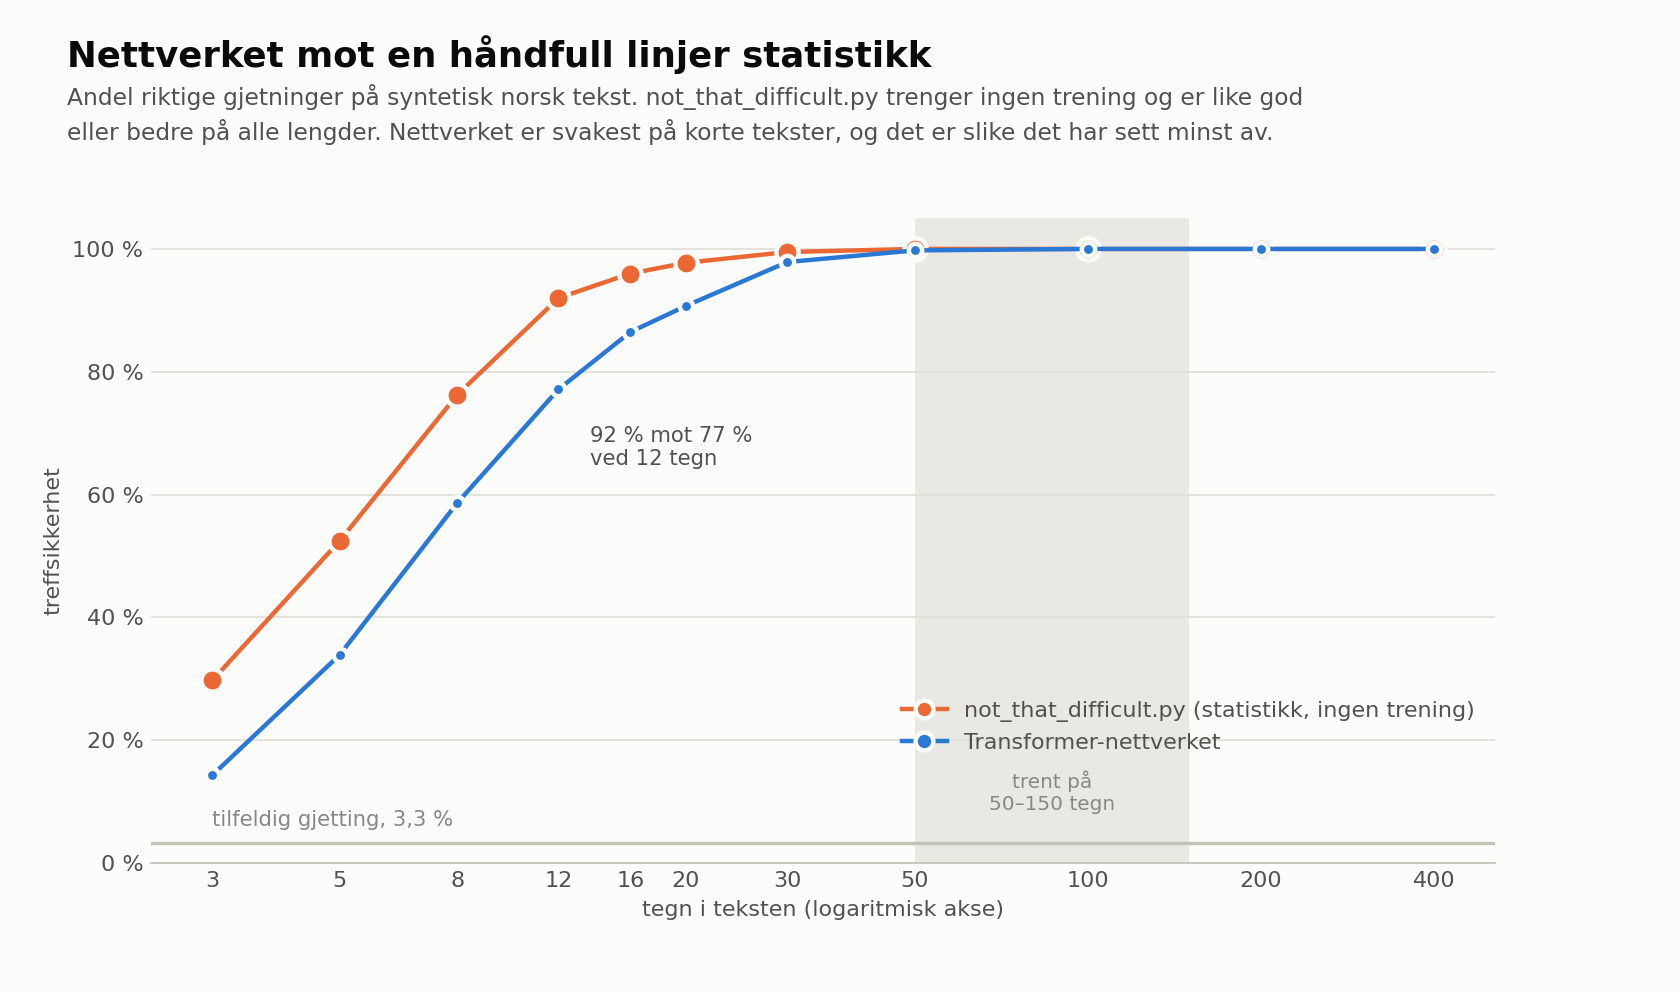

In [18]:
figur(pc.fig_accuracy, "4_treffsikkerhet.png", modell, width=900)

Statistikken ligger klart foran på korte tekster. Men sammenligningen er skjev: nettverket er testet på lengder det aldri er trent på (det grå feltet viser hva det er trent på). Rettferdig er det å trene hver modell på lengden den testes på, så her er alle fire trinn trent og testet på hver lengde.

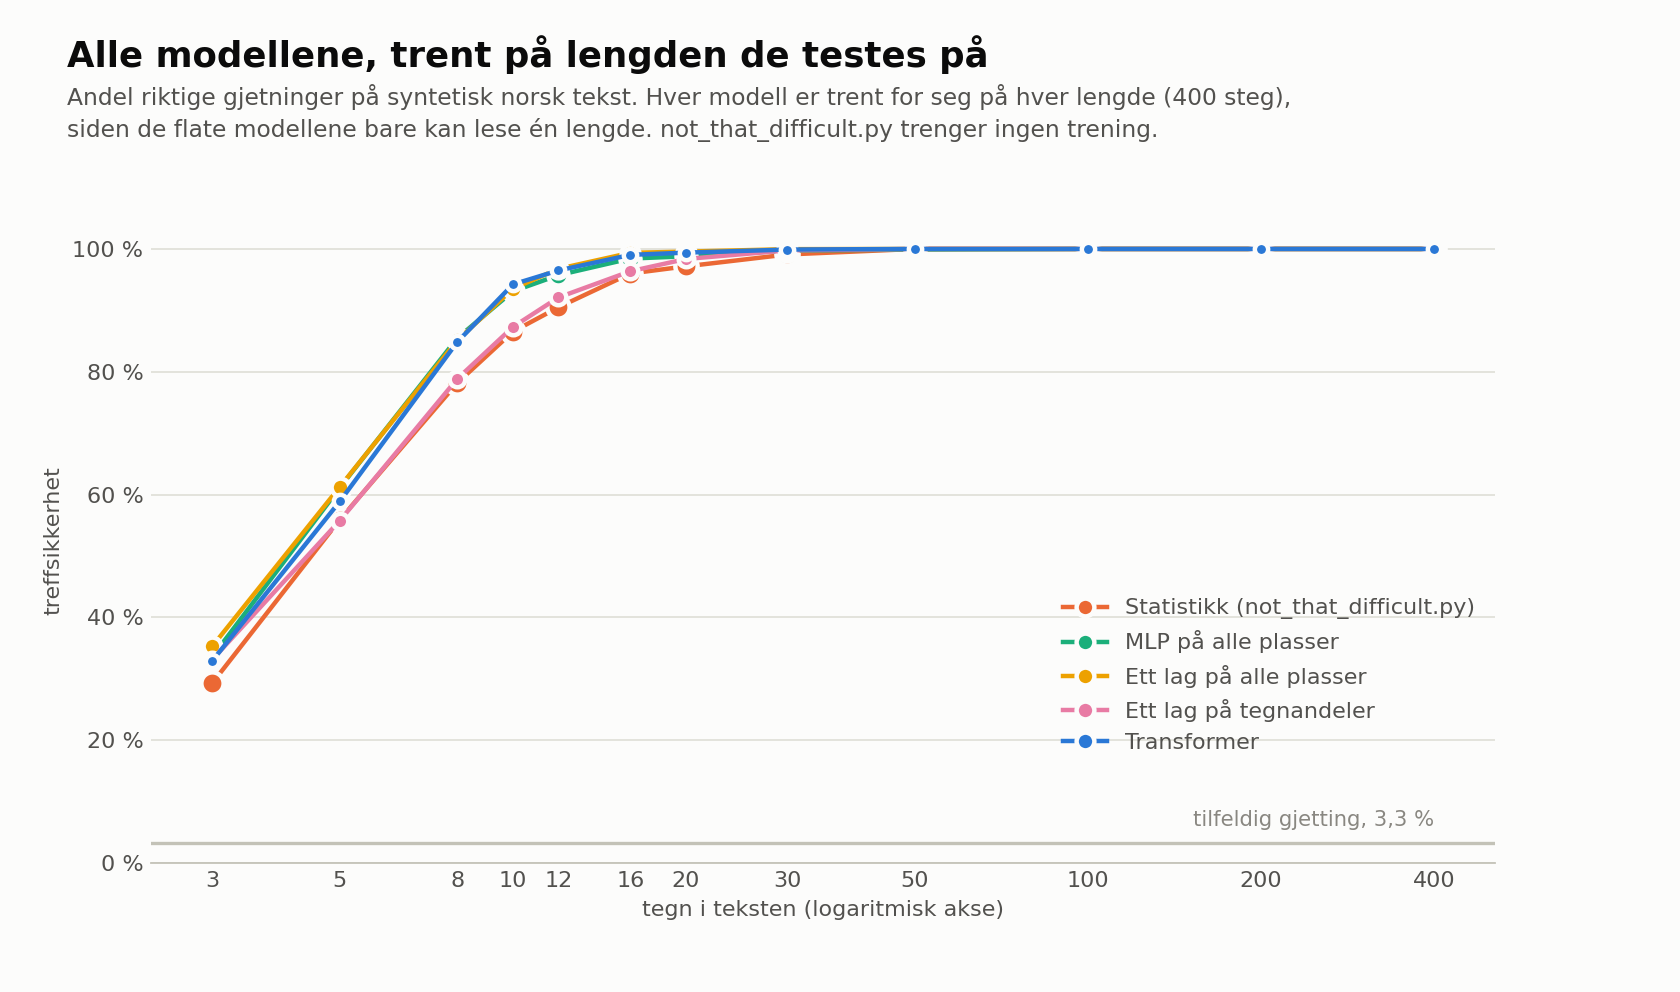

In [19]:
lengder = figur(pc.fig_trappen, "5_trappen_per_lengde.png", width=900)

In [20]:
i10, i30 = lengder["lengths"].index(10), lengder["lengths"].index(30)
print(f"{'':<27} {'10 tegn':>8} {'30 tegn':>8}")
for i, navn in enumerate([n for n, _ in tp.RUNGS], 1):
    print(f"{i}  {navn:<24} {lengder[navn][i10]:>8.1%} {lengder[navn][i30]:>8.1%}")
print(f"{'Statistikk':<27} {lengder['Statistikk'][i10]:>8.1%} {lengder['Statistikk'][i30]:>8.1%}")
print("\n(én trening per tall, 400 steg, syntetiske tekster)")

                             10 tegn  30 tegn
1  Transformer                 94.2%    99.9%
2  MLP på alle plasser         93.1%    99.7%
3  Ett lag på alle plasser     93.5%   100.0%
4  Ett lag på tegnandeler      87.3%    99.8%
Statistikk                     86.5%    99.1%

(én trening per tall, 400 steg, syntetiske tekster)


Trent på riktig lengde ligger tre av fire nettverk klart over statistikken på 10 tegn, og trinn 4 er likt med den. På 30 tegn ligger alle på 99–100 %, litt over statistikken. Svakheten i figuren handlet altså mest om hva nettverket ble trent på, og ikke om hva 10 bokstaver rekker å fortelle. Chi-kvadrat er heller ikke den beste måten å bruke frekvenstabellen på for veldig korte tekster.

Og på ekte tekst, med de samme vinduene som i seksjon 6:

In [21]:
if ekte:
    abc, frekvenser = nd.load_frequencies(Path("vanligst.csv"))
    print(f"{'vindu':>6} {'tester':>7} {'nettverk':>9} {'statistikk':>11}")
    for L, (X, y) in ekte.items():
        print(f"{L:>6} {len(X):>7} {cc.accuracy(modell, X, y):>9.1%} {pc.stats_accuracy(X, y):>11.1%}")

 vindu  tester  nettverk  statistikk
    30    3390     90.4%       88.5%
    50    2040     92.4%       91.2%
   100    1020     91.7%       94.1%


Omtrent uavgjort på ekte tekst: nettverket er litt bedre på de korteste vinduene og statistikken på 100 tegn, og forskjellene er små. Det som ikke er uavgjort er regningen:

In [22]:
def linjer(*deler):
    return sum(len(inspect.getsource(d).splitlines()) for d in deler)


lagret = cc.load_saved()
param = sum(p.numel() for p in modell.parameters())
rader = [
    ("parametre", f"{param:,}".replace(",", " "), "0"),
    ("treningstekster", f"{historikk[-1]['texts']:,}".replace(",", " "), "0"),
    ("treningstid", f"{lagret['seconds']:.0f} s", "0 s"),
    ("linjer kode", linjer(cc.make_plain, cc.make_batch, cc.Cracker, cc.train), linjer(nd.shift, nd.load_frequencies, nd.decipher)),
]
print(f"{'':<17} {'transformer':>12} {'statistikk':>11}")
for navn, a, b in rader:
    print(f"{navn:<17} {a:>12} {b:>11}")

                   transformer  statistikk
parametre              103 838           0
treningstekster         51 200           0
treningstid                4 s         0 s
linjer kode                 92          32


## 9. Hva lærte vi?

**Nettverket virker.** Uten å få vite noe som helst om cæsar-chiffer fant det ut av et par tusen eksempler at det er bokstavfordelingen som teller. Det klarte alle fire filene og er nesten perfekt på syntetiske tekster på 100 tegn. Det er litt imponerende.

**Men prisen står ikke i forhold til det det gir.** På ekte tekst er nettverk og statistikk omtrent likt, med forskjeller som er små og går begge veier. På korte syntetiske tekster vinner statistikken mot den ferdige modellen, men det er mest fordi den ble trent på 50–150 tegn: trent på riktig lengde er nettverkene omtrent like gode eller bedre. Nettverket taper altså ikke på treffsikkerhet, det taper på regningen: over 100 000 parametre, over 50 000 treningstekster, en datagenerator og en treningsløkke. Treningen er rask på GPU, men den må gjøres, og gjøres på nytt hvis alfabetet endres. Statistikken koster ingenting av det.

**Trappen ender i statistikken.** Vi kunne ta bort nesten alt: transformeren, oppmerksomheten, den skjulte delen. Det siste trinnet, ett lag på tegnandelene, er den klassiske metoden tegnet som et nettverk. Et så lite nettverk gjør i praksis det samme som statistikken.

**Og det er en sirkel i det.** Nettverket lærte seg bokstavfordelingen fra eksempler som vi selv genererte fra bokstavfordelingen. Statistikken bruker tabellen direkte. Nettverket har altså brukt all den treningen på å finne igjen noe vi allerede visste.

**Når gir ML mening?** Når man ikke kjenner strukturen i problemet. Her kjente vi den, og da er det bedre å bruke den. Ærlig forbehold: statistikken er heller ikke perfekt (chi-kvadrat tar feil på `i4.txt`), og på veldig korte tekster har ingen av dem nok å gå på.

## 10. Prøv selv

Bytt ut teksten og kjør cellen. Teksten kodes først med en forskyvning du ikke ser, og så knekkes den av begge.

In [23]:
hemmelig = cc.shift_text("dette er en hemmelig melding til deg", 11)   # bytt gjerne ut med din egen kodede tekst
print("Kodet:     ", hemmelig, "\n")

k, sikkerhet = cc.crack_text(modell, hemmelig)
print(f"Nettverket: forskyvning {k} (sikkerhet {sikkerhet:.0%})  ->  {cc.shift_text(hemmelig, -k)}")

abc, frekvenser = nd.load_frequencies(Path("vanligst.csv"))
klartekst, k = nd.decipher(hemmelig, abc, frekvenser)
print(f"Statistikk: forskyvning {k}                    ->  {klartekst}")

Kodet:      opaapkpåkpykspxxpwtrkxpwotyrkatwkopr 

Nettverket: forskyvning 11 (sikkerhet 100%)  ->  dette er en hemmelig melding til deg
Statistikk: forskyvning 11                    ->  dette er en hemmelig melding til deg
